# 03 Métricas por empresa, sector e índice

**Proyecto:** Análisis de estrategias de inversión en el S&P 500

En este notebook calculo las métricas que necesito para responder a las preguntas del proyecto: cuánto ha subido cada empresa, cuánto riesgo ha tenido, cuál ha sido su peor caída y si ha ido mejor o peor que el índice. También calculo lo mismo por sectores y para un reparto del dinero a partes iguales entre todas las empresas.

### Qué voy a hacer

Calculo la rentabilidad de cada día de cada empresa.

Calculo las métricas de cada empresa: rentabilidad total, rentabilidad anual, riesgo y peor caída.

Comparo cada empresa con el índice.

Calculo las mismas métricas por sectores.

Creo un reparto a partes iguales entre todas las empresas para compararlo con el índice.

### Datos

Parto de los datos limpios de Data/Processed y guardaré los resultados en la misma carpeta, para usarlos después en SQL y Power BI.

## 1. Cargar los datos

Primero conecto Google Drive, porque ahí tengo guardados los CSV limpios que generé en el notebook anterior.

In [ ]:
# Conecto Google Drive para poder leer mis archivos
from google.colab import drive
drive.mount('/content/drive')

# Importo pandas para trabajar con tablas
import pandas as pd

# Carpeta del Drive donde están los datos limpios
RUTA_PROCESSED = "/content/drive/MyDrive/PORTFOLIO MARCOS GUERRERO SANCHEZ/analisis-estrategias-inversion/Data/Processed/"

# Cargo los tres archivos limpios
# Con el parámetro parse_dates la columna Date se lee como fecha y no como texto
# Lo necesito porque en la limpieza quité la hora y la columna se guardó como texto
empresas = pd.read_csv(RUTA_PROCESSED + "empresas_limpias.csv")
precios = pd.read_csv(RUTA_PROCESSED + "precios_limpios.csv", parse_dates=["Date"])
indice = pd.read_csv(RUTA_PROCESSED + "indice_limpio.csv", parse_dates=["Date"])

# Compruebo el tamaño de cada tabla (filas y columnas)
print("Empresas:", empresas.shape)
print("Precios:", precios.shape)
print("Índice:", indice.shape)

Mounted at /content/drive
Empresas: (461, 4)
Precios: (1248372, 7)
Índice: (2708, 6)


## 2. Rentabilidad diaria de cada empresa

Para comparar empresas voy a basarme en cuánto sube o baja cada acción en porcentaje.

Por eso calculo la rentabilidad diaria: cuánto ha cambiado el precio de cierre de cada empresa respecto al día anterior, en %. A partir de ella calcularé todas las demás métricas.

In [ ]:
# Ordeno la tabla por empresa y por fecha
# Así los días de cada empresa van seguidos y en orden
precios = precios.sort_values(["ticker", "Date"])

# Calculo cuánto sube o baja cada empresa de un día a otro
# groupby("ticker") hace el cálculo por separado para cada empresa
# pct_change() compara el precio de cada día con el del día anterior (0.02 significa que sube un 2 %)
# Pongo fill_method=None para que no salga un aviso de pandas
precios["rentabilidad_diaria"] = precios.groupby("ticker")["Close"].pct_change(fill_method=None)

# Miro las primeras filas para ver si ha salido bien
precios[["Date", "ticker", "Close", "rentabilidad_diaria"]].head()

,Date,ticker,Close,rentabilidad_diaria
24372,2016-01-04,A,37.356049,NaN
24373,2016-01-05,A,37.227505,-0.003441
24374,2016-01-06,A,37.392761,0.004439
24375,2016-01-07,A,35.804504,-0.042475
24376,2016-01-08,A,35.428108,-0.010513


En la tabla se ve cómo se movió Agilent (ticker A) sus primeros días.

Close es el precio de la acción al cerrar la bolsa ese día, y rentabilidad_diaria es cuánto ha subido o bajado respecto al día anterior. Si el número es positivo la acción subió, y si es negativo bajó. Para verlo en porcentaje hay que multiplicarlo por 100: por ejemplo, -0.003441 significa que bajó un 0,34 %.

El primer día sale NaN porque no hay un día anterior con el que comparar.

Normalmente los cambios son pequeños, de menos de un 1 o 2 % al día. El 7 de enero de 2016 Agilent bajó más de un 4 %, que coincide con la caída de la bolsa china de principios de ese año.

In [ ]:
# Muestro las mismas filas en porcentaje para que se entienda mejor
# Multiplico por 100 y redondeo a 2 decimales. Solo es para verlo, la tabla no cambia
(precios["rentabilidad_diaria"].head() * 100).round(2)

,rentabilidad_diaria
24372,NaN
24373,-0.34
24374,0.44
24375,-4.25
24376,-1.05


## 3. Rentabilidad diaria del índice

Hago lo mismo con el índice (SPY), para luego poder comparar cada empresa con el mercado.

In [ ]:
# Ordeno el índice por fecha
indice = indice.sort_values("Date")

# Calculo cuánto sube o baja el índice de un día a otro
# Aquí no uso groupby porque solo hay una serie de precios, la de SPY
indice["rentabilidad_diaria"] = indice["Close"].pct_change(fill_method=None)

# Miro las primeras filas para ver si ha salido bien
indice[["Date", "Close", "rentabilidad_diaria"]].head()

,Date,Close,rentabilidad_diaria
0,2016-01-04,169.051758,NaN
1,2016-01-05,169.337692,0.001691
2,2016-01-06,167.201660,-0.012614
3,2016-01-07,163.190247,-0.023991
4,2016-01-08,161.398895,-0.010977


El índice también bajó esos días, un 2,4 % el 7 de enero. Así que la caída de Agilent no fue solo cosa suya, todo el mercado bajó, aunque ella cayó más.

Esto es justo lo que quiero comparar en el proyecto: si cada empresa ha ido mejor o peor que el mercado.

## 4. Rentabilidad total de cada empresa

Calculo cuánto ha subido o bajado cada empresa desde el primer día hasta el último. Para eso comparo su precio del último día con el del primero.

Por ejemplo, si una acción valía 100 dólares en 2016 y ahora vale 300, ha subido un 200 %.


In [ ]:
# Busco el primer y el último precio de cada empresa
# groupby("ticker") separa las filas por empresa
# first() coge el primer valor de cada empresa y last() el último
# Funciona porque antes ordené la tabla por empresa y fecha
primer_precio = precios.groupby("ticker")["Close"].first()
ultimo_precio = precios.groupby("ticker")["Close"].last()

# Calculo cuánto ha subido cada empresa en total
# La cuenta es: (precio final - precio inicial) / precio inicial
rentabilidad_total = (ultimo_precio - primer_precio) / primer_precio

# Miro las 10 empresas que más han subido
# sort_values con ascending=False las ordena de mayor a menor
(rentabilidad_total.sort_values(ascending=False).head(10) * 100).round(1)

,Close
ticker,
NVDA,29005.9
AMD,21853.1
MU,7263.8
FIX,6654.0
LITE,4841.1
LRCX,4637.9
ANET,4380.4
PWR,3445.4
STX,3349.5


In [ ]:
# Miro las 10 empresas que más han subido
# Multiplico por 100 para verlo en porcentaje y redondeo a 1 decimal
# Con rename() le pongo nombre a la columna, porque si no aparece como "Close"
(rentabilidad_total.sort_values(ascending=False).head(10) * 100).round(1).rename("Rentabilidad total (%)")

,Rentabilidad total (%)
ticker,
NVDA,29005.9
AMD,21853.1
MU,7263.8
FIX,6654.0
LITE,4841.1
LRCX,4637.9
ANET,4380.4
PWR,3445.4
STX,3349.5


In [ ]:
# Miro las 10 empresas que menos han subido o que han bajado
# Sin ascending=False las ordena de menor a mayor, así salen las peores primero
(rentabilidad_total.sort_values().head(10) * 100).round(1).rename("Rentabilidad total (%)")

,Rentabilidad total (%)
ticker,
SKYD,-75.4
PCG,-73.2
NCLH,-73.2
VTRS,-58.5
KHC,-50.0
CCL,-43.4
CHTR,-41.8
HRL,-34.9
APTV,-34.7


En el otro extremo hay empresas que hoy valen menos que en 2016, aunque el mercado haya subido mucho. Las dos compañías de cruceros (Norwegian y Carnival) han perdido más de la mitad de su valor por el parón de la pandemia, y PG&E, una eléctrica de California, cayó por los incendios de 2017 y 2018.

También aparecen varias de alimentación y consumo, como Kraft Heinz, Hormel o Nike.

Se ve bastante claro que arriba están las empresas de chips e inteligencia artificial y abajo los cruceros, la televisión tradicional y la alimentación.

## 5. Rentabilidad anual de cada empresa

La rentabilidad total dice cuánto ha subido una empresa en casi 11 años, pero es difícil de interpretar. Por eso calculo también la rentabilidad anual: cuánto habría subido de media cada año para llegar a ese resultado.

Es la forma normal de comparar inversiones, porque así se puede comparar con lo que da un depósito o un fondo, que siempre se expresan en % al año.

In [ ]:
# Calculo cuántos años de datos tengo
# Resto la primera fecha a la última y lo divido entre 365.25 para pasarlo a años
# El .25 es por los años bisiestos
dias_totales = (precios["Date"].max() - precios["Date"].min()).days
anios = dias_totales / 365.25

print("Años de datos:", round(anios, 2))

# Calculo la rentabilidad anual de cada empresa
# La cuenta es: cuánto vale ahora por cada euro invertido, elevado a 1 entre los años, menos 1
rentabilidad_anual = (1 + rentabilidad_total) ** (1 / anios) - 1

# Miro las 10 empresas con más rentabilidad anual
(rentabilidad_anual.sort_values(ascending=False).head(10) * 100).round(1).rename("Rentabilidad anual (%)")


Años de datos: 10.76


,Rentabilidad anual (%)
ticker,
NVDA,69.4
AMD,65.0
MU,49.1
FIX,47.9
LITE,43.7
LRCX,43.1
ANET,42.4
PWR,39.3
STX,39.0


En rentabilidad anual los números se entienden mucho mejor. Nvidia ha dado casi un 70 % cada año, y todas las de la lista están por encima del 38 % anual.

Para comparar, un fondo que siga al S&P 500 suele dar alrededor de un 10 % al año.

El orden es el mismo que en la rentabilidad total, porque todas las empresas tienen los mismos años de datos. Lo que cambia es que ahora las cifras se pueden comparar con cualquier otra inversión.

## 6. Riesgo de cada empresa

La rentabilidad solo cuenta la mitad de la historia. Dos empresas pueden haber subido lo mismo, pero una habiendo ido poco a poco y otra con subidas y bajadas muy bruscas. La segunda es mucho más arriesgada.

Para medirlo calculo la volatilidad: cuánto se mueve el precio de una empresa de un día a otro. Si una empresa sube y baja mucho cada día, tiene

In [ ]:
# Calculo cuánto varían las rentabilidades diarias de cada empresa
# std() es la desviación típica: mide cuánto se alejan los valores de su media
# Cuanto más alta, más se mueve el precio de un día para otro
volatilidad_diaria = precios.groupby("ticker")["rentabilidad_diaria"].std()

# Paso la volatilidad diaria a anual
# Multiplico por la raíz de 252, que son los días que abre la bolsa en un año
volatilidad_anual = volatilidad_diaria * (252 ** 0.5)

# Miro las 10 empresas con más riesgo
(volatilidad_anual.sort_values(ascending=False).head(10) * 100).round(1).rename("Volatilidad anual (%)")

,Volatilidad anual (%)
ticker,
SMCI,71.4
NCLH,60.9
AMD,60.1
TSLA,58.4
PCG,58.1
APA,58.0
COHR,57.6
LITE,57.4
XYZ,56.7


Las empresas más volátiles son las que más se mueven, hacia arriba o hacia abajo. Por eso en esta lista hay empresas que han subido muchísimo, como AMD, y otras que han caído mucho, como Norwegian o PG&E.

Se mueven entre un 56 % y un 71 % al año, mientras que el índice suele estar en torno al 15-18 %. Es decir, son unas tres o cuatro veces más arriesgadas que el mercado.

La volatilidad no dice si se gana o se pierde, solo cuánto se mueve el precio.

## 7. La peor caída de cada empresa

La volatilidad es útil pero cuesta de imaginar. Una forma más clara de ver el riesgo es la peor caída: cuánto llegó a bajar una empresa desde su punto más alto hasta el más bajo que vino después.

Por ejemplo, si una acción llegó a valer 100 dólares y después bajó hasta 60, su peor caída fue del 40 %. Eso es lo que habría tenido que aguantar alguien que la comprara justo en el peor momento.

In [ ]:
# Calculo el precio más alto que ha tenido cada empresa hasta cada día
# cummax() va guardando el máximo que ha visto hasta ese momento
# groupby("ticker") hace el cálculo por separado en cada empresa
precios["maximo_hasta_ahora"] = precios.groupby("ticker")["Close"].cummax()

# Calculo cuánto está cada día por debajo de ese máximo
# Si el precio está en su máximo sale 0, y si ha bajado sale un número negativo
precios["caida"] = (precios["Close"] - precios["maximo_hasta_ahora"]) / precios["maximo_hasta_ahora"]

# Me quedo con la peor caída de cada empresa
peor_caida = precios.groupby("ticker")["caida"].min()

# Miro las 10 empresas con peores caídas
(peor_caida.sort_values().head(10) * 100).round(1).rename("Peor caída (%)")

,Peor caída (%)
ticker,
PCG,-94.6
APA,-93.5
HAL,-91.4
SKYD,-91.2
TRGP,-90.8
CCL,-90.4
FANG,-88.7
DVN,-88.5
OXY,-88.4


Todas estas empresas llegaron a perder más del 88 % de su valor en algún momento. PG&E perdió un 94,6 %.

Seis de las diez son de petróleo y gas. En 2020, con la pandemia, el consumo de combustible se hundió y el precio del petróleo llegó a estar en negativo unos días, así que todo el sector cayó a la vez.

Lo llamativo es que una caída tan grande no significa que la empresa haya perdido dinero a largo plazo: varias de estas petroleras se recuperaron después. Pero por el camino alguien que las tuviera vio bajar su inversión casi un 90 %.

El índice entero, en cambio, cayó como mucho un 34 % en marzo de 2020. Es un buen ejemplo de por qué no conviene poner todo el dinero en una sola empresa.

## 8. Junto todas las métricas en una tabla

Hasta ahora tengo las métricas por separado. Ahora las junto todas en una sola tabla, con una fila por empresa, y le añado el nombre y el sector.

Esta será la tabla principal del proyecto: la que usaré en SQL y en Power BI.

In [ ]:
# Junto las métricas que he calculado en una sola tabla
# Cada métrica es una columna y cada empresa una fila
metricas = pd.DataFrame({
    "rentabilidad_total": rentabilidad_total,
    "rentabilidad_anual": rentabilidad_anual,
    "volatilidad_anual": volatilidad_anual,
    "peor_caida": peor_caida
})

# Convierto el ticker en una columna normal
# reset_index() saca el ticker del índice y lo pone como una columna más
metricas = metricas.reset_index()

# Le añado el nombre y el sector de cada empresa
# merge() une las dos tablas usando la columna que tienen en común, el ticker
metricas = metricas.merge(empresas, on="ticker")

# Miro cómo ha quedado
print("Tamaño de la tabla:", metricas.shape)
metricas.head()

Tamaño de la tabla: (461, 8)


,ticker,rentabilidad_total,rentabilidad_anual,volatilidad_anual,peor_caida,nombre,sector,industria
0,A,3.565258,0.151528,0.280483,-0.431929,Agilent Technologies,Salud,Life Sciences Tools & Services
1,AAPL,13.211010,0.279666,0.288625,-0.385159,Apple Inc.,Tecnología,"Technology Hardware, Storage & Peripherals"
2,ABBV,6.445405,0.205069,0.260057,-0.450898,AbbVie,Salud,Biotechnology
3,ABT,1.852997,0.102312,0.240301,-0.396400,Abbott Laboratories,Salud,Health Care Equipment
4,ACGL,3.379300,0.147087,0.269885,-0.538398,Arch Capital Group,Financiero,Property & Casualty Insurance


In [ ]:
# Muestro las métricas en porcentaje para que se entiendan mejor
# Hago una copia para no cambiar la tabla original
vista = metricas.copy()

# Multiplico por 100 las cuatro columnas de métricas y redondeo a 1 decimal
columnas = ["rentabilidad_total", "rentabilidad_anual", "volatilidad_anual", "peor_caida"]
vista[columnas] = (vista[columnas] * 100).round(1)

vista.head()

,ticker,rentabilidad_total,rentabilidad_anual,volatilidad_anual,peor_caida,nombre,sector,industria
0,A,356.5,15.2,28.0,-43.2,Agilent Technologies,Salud,Life Sciences Tools & Services
1,AAPL,1321.1,28.0,28.9,-38.5,Apple Inc.,Tecnología,"Technology Hardware, Storage & Peripherals"
2,ABBV,644.5,20.5,26.0,-45.1,AbbVie,Salud,Biotechnology
3,ABT,185.3,10.2,24.0,-39.6,Abbott Laboratories,Salud,Health Care Equipment
4,ACGL,337.9,14.7,27.0,-53.8,Arch Capital Group,Financiero,Property & Casualty Insurance


Ya tengo todas las métricas en una sola tabla, con una fila por empresa. Por ejemplo, Apple ha dado un 28,2 % al año, se mueve un 28,9 % anual y en algún momento llegó a caer un 38,5 % desde su máximo.

Las 461 empresas siguen estando, así que no he perdido ninguna al unir las tablas.

La columna industria se queda en inglés, porque son nombres muy específicos y en el dashboard voy a usar sobre todo el sector.

## 9. Comparo cada empresa con el índice

Esta es la pregunta principal del proyecto: ¿cuántas empresas lo han hecho mejor que el mercado?

Para saberlo calculo la rentabilidad del índice en el mismo periodo y la comparo con la de cada empresa.

In [ ]:
# Calculo cuánto ha subido el índice desde el primer día hasta el último
# Es la misma cuenta que hice con las empresas: (precio final - precio inicial) / precio inicial
primer_precio_indice = indice["Close"].iloc[0]
ultimo_precio_indice = indice["Close"].iloc[-1]

rentabilidad_indice = (ultimo_precio_indice - primer_precio_indice) / primer_precio_indice

# Calculo también su rentabilidad anual, igual que hice con las empresas
rentabilidad_anual_indice = (1 + rentabilidad_indice) ** (1 / anios) - 1

print("Rentabilidad total del índice:", round(rentabilidad_indice * 100, 1), "%")
print("Rentabilidad anual del índice:", round(rentabilidad_anual_indice * 100, 1), "%")

Rentabilidad total del índice: 360.6 %
Rentabilidad anual del índice: 15.2 %


In [ ]:
# Añado a la tabla si cada empresa ha ido mejor que el índice
# La comparación da True si la empresa ha subido más que el índice y False si no
metricas["bate_al_indice"] = metricas["rentabilidad_total"] > rentabilidad_indice

# Cuento cuántas empresas han ido mejor
empresas_mejores = metricas["bate_al_indice"].sum()

print("Empresas que baten al índice:", empresas_mejores, "de", len(metricas))
print("Porcentaje:", round(empresas_mejores / len(metricas) * 100, 1), "%")

Empresas que baten al índice: 149 de 461
Porcentaje: 32.3 %


In [ ]:
print("Rentabilidad anual del índice:", round(rentabilidad_anual_indice * 100, 1), "%")

Rentabilidad anual del índice: 15.2 %


In [ ]:
# Calculo el riesgo del índice, para poder compararlo con el de las empresas
# Es el mismo cálculo que hice con las empresas: desviación típica por la raíz de 252
volatilidad_anual_indice = indice["rentabilidad_diaria"].std() * (252 ** 0.5)

# Calculo la peor caída del índice
# cummax() guarda el máximo visto hasta cada día, y comparo el precio con ese máximo
maximo_indice = indice["Close"].cummax()
caida_indice = (indice["Close"] - maximo_indice) / maximo_indice
peor_caida_indice = caida_indice.min()

print("Riesgo anual del índice:", round(volatilidad_anual_indice * 100, 1), "%")
print("Peor caída del índice:", round(peor_caida_indice * 100, 1), "%")

Riesgo anual del índice: 17.7 %
Peor caída del índice: -33.7 %


Solo 149 de las 461 empresas (un 32,3 %) han subido más que el índice. Es decir, **más de dos tercios de las empresas del S&P 500 lo han hecho peor que el propio S&P 500**.

Puede parecer raro, pero tiene explicación: el índice no reparte el dinero por igual, sino que da más peso a las empresas grandes. Así que las que más han subido (Nvidia, Apple, Microsoft) tiran mucho de él, aunque la mayoría se quede por detrás.

Además, una empresa como mucho puede perder el 100 %, pero puede ganar un 29.000 %, como Nvidia. Unas pocas ganadoras muy grandes compensan a muchas que van regular.

Esto responde a la pregunta principal del proyecto: la subida del índice no viene de todo el mercado, sino de un grupo pequeño de empresas.

## 10. Métricas por sector

Ahora agrupo las empresas por sector para ver cuáles han ido mejor y cuáles han tenido más riesgo.

Uso la mediana en vez de la media, porque empresas como Nvidia, con un 28.000 %, desvirtúan la media de todo su sector. La mediana es el valor que está justo en el medio, así que refleja mejor cómo le ha ido a la empresa típica de cada sector.

In [ ]:
# Agrupo las empresas por sector y calculo la mediana de cada métrica
# median() coge el valor que queda en el medio al ordenar los datos
# agg() permite calcular varias cosas a la vez
sectores = metricas.groupby("sector").agg(
    empresas=("ticker", "count"),
    rentabilidad_anual=("rentabilidad_anual", "median"),
    volatilidad_anual=("volatilidad_anual", "median"),
    peor_caida=("peor_caida", "median")
)

# Ordeno de mayor a menor rentabilidad
sectores = sectores.sort_values("rentabilidad_anual", ascending=False)

# Lo muestro en porcentaje para que se lea mejor
vista = sectores.copy()
columnas = ["rentabilidad_anual", "volatilidad_anual", "peor_caida"]
vista[columnas] = (vista[columnas] * 100).round(1)
vista

,empresas,rentabilidad_anual,volatilidad_anual,peor_caida
sector,,,,
Tecnología,68,21.2,37.2,-56.6
Industrial,70,13.9,28.1,-46.5
Financiero,74,13.1,30.0,-51.2
Energía,20,12.9,40.1,-79.0
Materiales,21,11.9,30.8,-55.1
Salud,57,11.8,30.0,-51.5
Consumo discrecional,44,11.7,35.4,-58.8
Comunicaciones,18,10.1,29.6,-56.7
Servicios públicos,29,9.7,22.5,-40.0


Solo Tecnología (21,2 % anual) supera al índice, que dio un 15,2 %. Industrial y Financiero se quedan muy cerca, y el resto bastante por debajo.

Lo que más me llama la atención es Energía: es el sector con más riesgo (40,1 % de volatilidad) y el que más cayó (-79 %), pero solo da un 12,9 % al año. Así que más riesgo no siempre significa más rentabilidad.

En el otro extremo, Servicios públicos es el más tranquilo (22,5 % de volatilidad y una caída del 40 %) y aun así da casi un 10 % anual.

Los que peor lo han hecho son Consumo básico e Inmobiliario, con menos de un 7 % al año.

Todos los sectores llegaron a caer más de un 40 %, mientras que el índice entero cayó como mucho un 34 %. Eso pasa porque los sectores no caen todos a la vez, así que el conjunto aguanta mejor que cualquiera de ellos por separado.

## 11. ¿Y si reparto el dinero a partes iguales?

El índice da más peso a las empresas grandes, así que las que más han subido (Nvidia, Apple, Microsoft) tiran mucho de él.

Para comprobarlo invento una cartera distinta: en lugar de dar más peso a las grandes, reparto el dinero a partes iguales entre las 461 empresas. Si el índice gana a este reparto, quedará claro que la subida viene sobre todo de las empresas grandes.

In [ ]:
# Calculo la rentabilidad media de todas las empresas en cada día
# groupby("Date") junta las 461 empresas de cada día y mean() calcula su media
# Es como repartir el dinero a partes iguales entre todas
rentabilidad_media_diaria = precios.groupby("Date")["rentabilidad_diaria"].mean()

# Convierto esas rentabilidades diarias en la evolución de la cartera
# Sumo 1 a cada día (para pasar de 0.02 a 1.02) y los voy multiplicando entre sí
# cumprod() multiplica cada valor por todos los anteriores
cartera_igual = (1 + rentabilidad_media_diaria).cumprod()

# La rentabilidad total es el valor final menos 1
rentabilidad_cartera_igual = cartera_igual.iloc[-1] - 1

# Calculo también su rentabilidad anual, igual que antes
rentabilidad_anual_cartera = (1 + rentabilidad_cartera_igual) ** (1 / anios) - 1

print("Reparto a partes iguales - total:", round(rentabilidad_cartera_igual * 100, 1), "%")
print("Reparto a partes iguales - anual:", round(rentabilidad_anual_cartera * 100, 1), "%")
print()
print("Índice - total:", round(rentabilidad_indice * 100, 1), "%")
print("Índice - anual:", round(rentabilidad_anual_indice * 100, 1), "%")

Reparto a partes iguales - total: 452.3 %
Reparto a partes iguales - anual: 17.2 %

Índice - total: 360.6 %
Índice - anual: 15.2 %


Me ha sorprendido el resultado: repartiendo el dinero a partes iguales sale un 17,2 % anual, más que el 15,2 % del índice.

Pero hay que tener cuidado con esta comparación, porque mi cartera usa las 461 empresas que están hoy en el índice. Alguien que hubiera invertido en 2016 habría comprado las que estaban entonces, y algunas de ellas quebraron o salieron del índice por ir mal. El índice real sí incluye a esas, y mi cartera no. Es el sesgo de supervivencia que ya anoté en la exploración.

Además, un reparto a partes iguales de verdad obliga a estar comprando y vendiendo todo el rato para mantener los pesos, lo que tiene comisiones e impuestos que aquí no estoy contando.

Así que la conclusión es más matizada: entre las empresas que han sobrevivido en el índice, a la empresa media le ha ido mejor que al índice. Pero eso no quita que solo el 32 % de ellas lo haya superado, porque la media sube mucho por culpa de unas pocas empresas que han subido una barbaridad.

## 12. Evolución día a día

Para el gráfico del dashboard necesito la evolución día a día del índice y del reparto a partes iguales. Pongo los dos empezando en 100, para que se puedan comparar aunque partan de precios distintos.

In [ ]:
# Calculo la evolución del índice empezando en 100
# Divido cada precio entre el primero y multiplico por 100
evolucion_indice = indice["Close"] / indice["Close"].iloc[0] * 100

# Hago lo mismo con la cartera a partes iguales, que ya empieza en 1
evolucion_cartera = cartera_igual * 100

# Junto las dos en una tabla, con la fecha
evolucion = pd.DataFrame({
    "Date": indice["Date"].values,
    "indice": evolucion_indice.values,
    "cartera_igual": evolucion_cartera.values
})

# Miro el principio y el final
print(evolucion.head(3))
print()
print(evolucion.tail(3))

        Date      indice  cartera_igual
0 2016-01-04  100.000000            NaN
1 2016-01-05  100.169140     100.186584
2 2016-01-06   98.905603      98.639492

           Date      indice  cartera_igual
2705 2026-10-07  459.752670     546.180026
2706 2026-10-08  457.806534     550.206773
2707 2026-10-09  460.551264     552.283233


In [ ]:
# El primer día de la cartera sale vacío porque no tiene rentabilidad diaria
# Lo pongo a 100 para que las dos series empiecen en el mismo punto
evolucion["cartera_igual"] = evolucion["cartera_igual"].fillna(100)

# Compruebo que ya no hay ningún hueco
evolucion.head(10)

,Date,indice,cartera_igual
0,2016-01-04,100.000000,100.000000
1,2016-01-05,100.169140,100.186584
2,2016-01-06,98.905603,98.639492
3,2016-01-07,96.532712,96.213071
4,2016-01-08,95.473065,95.108461
5,2016-01-11,95.567587,94.920818
6,2016-01-12,96.338678,95.550815
7,2016-01-13,93.935911,93.049967
8,2016-01-14,95.478048,94.401604
9,2016-01-15,93.428490,92.604797


## 13. Guardo los resultados

Guardo las tablas que he calculado en Data/Processed, para usarlas después en SQL y en Power BI.

In [ ]:
# Guardo las tres tablas que voy a usar más adelante
# index=False evita que se añada una columna extra con la numeración de las filas
metricas.to_csv(RUTA_PROCESSED + "metricas_empresas.csv", index=False)
evolucion.to_csv(RUTA_PROCESSED + "evolucion.csv", index=False)

# La tabla de sectores tiene el sector como índice, así que uso reset_index()
# para que el sector se guarde como una columna más
sectores.reset_index().to_csv(RUTA_PROCESSED + "metricas_sectores.csv", index=False)

# Compruebo el tamaño de lo que he guardado
print("Métricas por empresa:", metricas.shape)
print("Métricas por sector:", sectores.shape)
print("Evolución:", evolucion.shape)

Métricas por empresa: (461, 9)
Métricas por sector: (11, 4)
Evolución: (2708, 3)


## 14. Gráficos

Hago algunos gráficos para ver mejor las conclusiones. Son gráficos sencillos para entender los datos; los que irán al dashboard los haré después en Power BI.

In [ ]:
# Importo la librería para hacer gráficos
# Se suele llamar plt por costumbre, igual que pandas se llama pd
import matplotlib.pyplot as plt

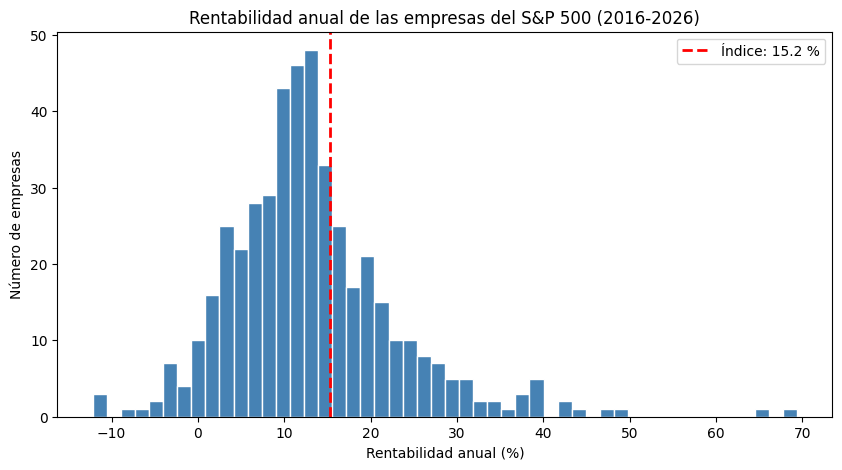

In [ ]:
# Creo el gráfico y le doy un tamaño (ancho, alto) en pulgadas
plt.figure(figsize=(10, 5))

# Dibujo un histograma con las rentabilidades anuales de las 461 empresas
# hist() agrupa los valores en barras para ver cuántas empresas hay en cada tramo
# bins=50 son las barras que quiero, y multiplico por 100 para verlo en porcentaje
plt.hist(metricas["rentabilidad_anual"] * 100, bins=50, color="steelblue", edgecolor="white")

# Dibujo una línea vertical roja donde está la rentabilidad del índice
# axvline() dibuja una línea vertical en el valor que le indico
plt.axvline(rentabilidad_anual_indice * 100, color="red", linestyle="--", linewidth=2,
            label=f"Índice: {rentabilidad_anual_indice * 100:.1f} %")

# Le pongo título y nombres a los ejes
plt.title("Rentabilidad anual de las empresas del S&P 500 (2016-2026)")
plt.xlabel("Rentabilidad anual (%)")
plt.ylabel("Número de empresas")

# Muestro la leyenda con el texto que puse en label
plt.legend()

# Dibujo el gráfico
plt.show()

En el histograma se ve que la mayoría de las empresas quedan a la izquierda de la línea roja, o sea, por debajo del índice. También se ve la cola hacia la derecha de las pocas empresas que han subido muchísimo.

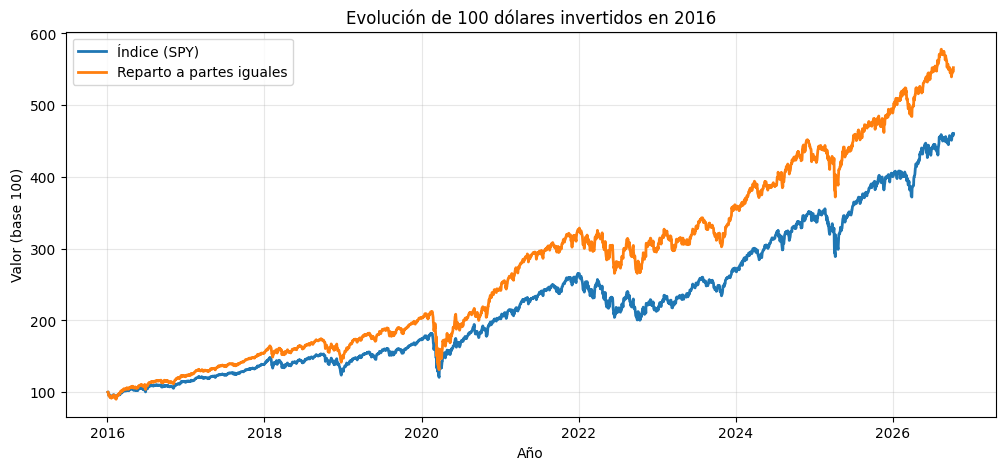

In [ ]:
plt.figure(figsize=(12, 5))

# Dibujo las dos líneas, una por cada serie
# plot() dibuja una línea uniendo los puntos de la tabla
plt.plot(evolucion["Date"], evolucion["indice"], label="Índice (SPY)", linewidth=2)
plt.plot(evolucion["Date"], evolucion["cartera_igual"], label="Reparto a partes iguales", linewidth=2)

plt.title("Evolución de 100 dólares invertidos en 2016")
plt.xlabel("Año")
plt.ylabel("Valor (base 100)")
plt.legend()

# Pongo una cuadrícula suave para que sea más fácil leer los valores
# alpha es la transparencia: 0.3 es bastante suave
plt.grid(alpha=0.3)

plt.show()

Se ven bien las dos caídas grandes: marzo de 2020 con la pandemia y todo 2022 con la subida de tipos. Las dos estrategias suben casi igual hasta que empiezan a separarse.

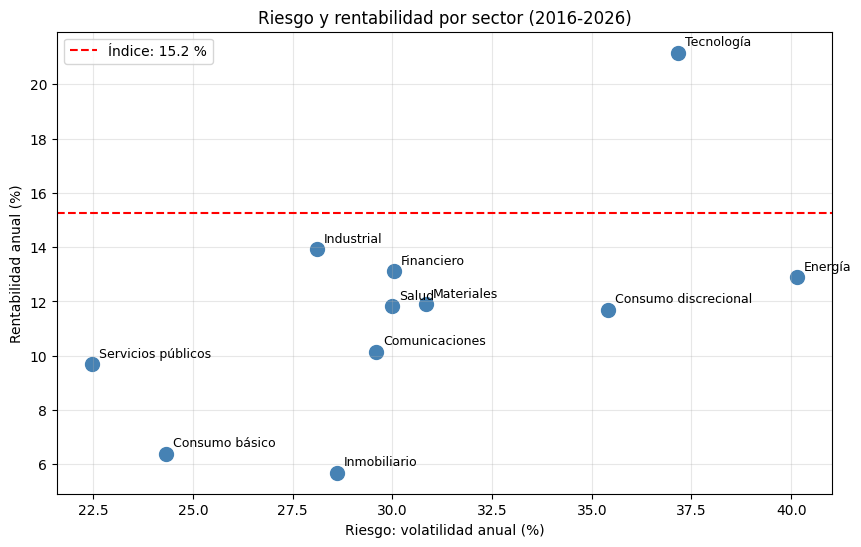

In [ ]:
plt.figure(figsize=(10, 6))

# Dibujo un punto por cada sector
# scatter() coloca un punto en la posición (x, y) de cada fila
# s=100 es el tamaño del punto
plt.scatter(sectores["volatilidad_anual"] * 100, sectores["rentabilidad_anual"] * 100,
            s=100, color="steelblue")

# Escribo el nombre de cada sector al lado de su punto
# Recorro los sectores y pongo su nombre usando sus valores de x e y
for sector in sectores.index:
    x = sectores.loc[sector, "volatilidad_anual"] * 100
    y = sectores.loc[sector, "rentabilidad_anual"] * 100
    plt.annotate(sector, (x, y), fontsize=9, xytext=(5, 5), textcoords="offset points")

# Línea horizontal con la rentabilidad del índice
plt.axhline(rentabilidad_anual_indice * 100, color="red", linestyle="--", linewidth=1.5,
            label=f"Índice: {rentabilidad_anual_indice * 100:.1f} %")

plt.title("Riesgo y rentabilidad por sector (2016-2026)")
plt.xlabel("Riesgo: volatilidad anual (%)")
plt.ylabel("Rentabilidad anual (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Cada punto es un sector. Cuanto más a la derecha, más riesgo, y cuanto más arriba, más rentabilidad.

Lo que más se ve es que Energía está muy a la derecha (mucho riesgo) pero no de las más altas, mientras que Servicios públicos está a la izquierda, con poco riesgo y una rentabilidad decente. Tecnología es el único sector por encima de la línea del índice.

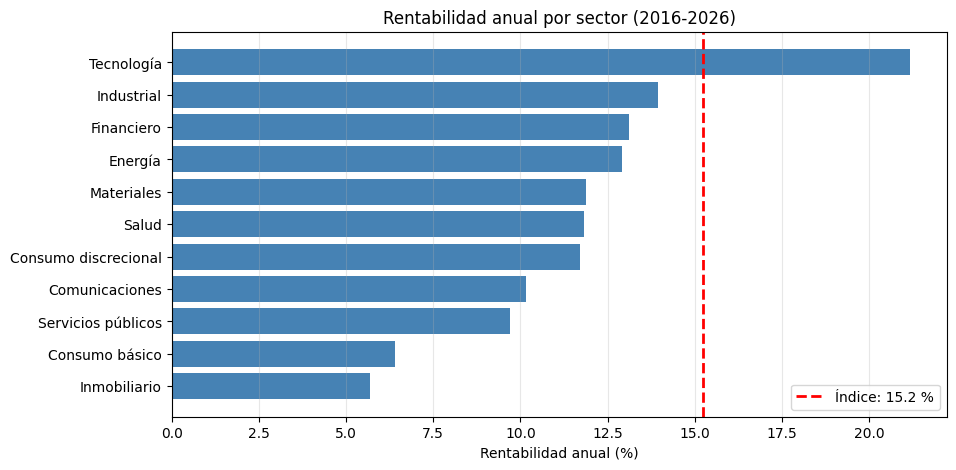

In [ ]:
plt.figure(figsize=(10, 5))

# Dibujo una barra por sector
# barh() hace barras horizontales, que van mejor cuando los nombres son largos
# Ordeno de menor a mayor para que la más alta quede arriba
sectores_ordenados = sectores.sort_values("rentabilidad_anual")
plt.barh(sectores_ordenados.index, sectores_ordenados["rentabilidad_anual"] * 100,
         color="steelblue")

# Línea vertical con la rentabilidad del índice
plt.axvline(rentabilidad_anual_indice * 100, color="red", linestyle="--", linewidth=2,
            label=f"Índice: {rentabilidad_anual_indice * 100:.1f} %")

plt.title("Rentabilidad anual por sector (2016-2026)")
plt.xlabel("Rentabilidad anual (%)")
plt.legend()
plt.grid(alpha=0.3, axis="x")
plt.show()

Solo Tecnología pasa la línea del índice. Industrial y Financiero se quedan cerca, y Consumo básico e Inmobiliario son los que peor lo han hecho, por debajo del 7 % anual.

## 14. Resumen

Estas son las conclusiones principales del notebook:

El índice ha dado un 15,2 % anual desde 2016, bastante más que su media histórica, que ronda el 10 %.

Solo 149 de las 461 empresas (un 32 %) han subido más que el índice. O sea que más de dos tercios lo han hecho peor que el propio S&P 500.

Las empresas que más han subido son casi todas de chips, centros de datos e infraestructura para la inteligencia artificial. Nvidia ha subido casi un 70 % al año.

Por sectores, solo Tecnología supera al índice. Energía es el sector con más riesgo y el que más cayó (-79 %), pero da menos rentabilidad que Industrial o Financiero, que son más tranquilos.

Repartiendo el dinero a partes iguales sale más que el índice (17,3 % frente a 15,3 %), pero hay que cogerlo con pinzas por el sesgo de supervivencia, porque uso solo las empresas que siguen hoy en el índice.

He guardado tres tablas en Data/Processed: metricas_empresas.csv, metricas_sectores.csv y evolucion.csv.

In [ ]:
# Imprimo el resumen con los números calculados, para que se actualice solo al cambiar los datos
print("RESUMEN DEL ANÁLISIS")
print("Periodo analizado:", precios["Date"].min().date(), "a", precios["Date"].max().date())
print("Años de datos:", round(anios, 2))
print("Empresas analizadas:", len(metricas))
print()
print("Índice (SPY)")
print("  Rentabilidad anual:", round(rentabilidad_anual_indice * 100, 1), "%")
print("  Riesgo anual:", round(volatilidad_anual_indice * 100, 1), "%")
print("  Peor caída:", round(peor_caida_indice * 100, 1), "%")
print()
print("Empresas")
print("  Rentabilidad anual media:", round(metricas["rentabilidad_anual"].mean() * 100, 1), "%")
print("  Rentabilidad anual mediana:", round(metricas["rentabilidad_anual"].median() * 100, 1), "%")
print("  Riesgo anual medio:", round(metricas["volatilidad_anual"].mean() * 100, 1), "%")
print("  Baten al índice:", empresas_mejores, "de", len(metricas),
      "(" + str(round(empresas_mejores / len(metricas) * 100, 1)) + " %)")
print()
print("Reparto a partes iguales")
print("  Rentabilidad anual:", round(rentabilidad_anual_cartera * 100, 1), "%")

RESUMEN DEL ANÁLISIS
Periodo analizado: 2016-01-04 a 2026-10-09
Años de datos: 10.76
Empresas analizadas: 461

Índice (SPY)
  Rentabilidad anual: 15.2 %
  Riesgo anual: 17.7 %
  Peor caída: -33.7 %

Empresas
  Rentabilidad anual media: 13.2 %
  Rentabilidad anual mediana: 12.1 %
  Riesgo anual medio: 32.1 %
  Baten al índice: 149 de 461 (32.3 %)

Reparto a partes iguales
  Rentabilidad anual: 17.2 %


In [29]:
# Compruebo si alguna empresa tiene menos riesgo que el índice
print("Riesgo del índice:", round(volatilidad_anual_indice * 100, 1), "%")
print("Empresa con menos riesgo:", round(metricas["volatilidad_anual"].min() * 100, 1), "%")
print("Empresas por debajo del índice:", (metricas["volatilidad_anual"] < volatilidad_anual_indice).sum())

Riesgo del índice: 17.7 %
Empresa con menos riesgo: 18.2 %
Empresas por debajo del índice: 0
